# 02 - Network Formation Simulation (Bala & Goyal, 2000)

This notebook implements the **noncooperative network formation** model from Bala & Goyal
(2000). Agents strategically form directed links to access information from others.
Link formation is costly, information decays over distance, and some agents are designated
as high-value **influencers**.

We test whether the resulting network follows the **Law of the Few** pattern, where a small
fraction of nodes attract a disproportionate share of incoming connections.

### Workflow
1. Baseline simulation with default parameters.
2. Comparative analysis across parameter variations.
3. Parameter sensitivity exploration.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.models.network_formation import NoncooperativeNetworkFormation
from src.visualization.simulation_plots import (
    plot_network_evolution,
    plot_comparative_results,
    plot_parameter_heatmap,
)

## Parameter Configuration

| Parameter | Description | Default |
|-----------|-------------|--------|
| `n_nodes` | Number of agents | 100 |
| `decay_parameter` | Information decay rate per hop ($\delta$) | 0.9 |
| `cost_parameter` | Per-link cost ($c$) | 0.1 |
| `heterogeneity_factor` | Value of influencer nodes vs regular nodes | 3.0 |
| `strategic_update_prob` | Probability a node uses best-response (vs random) | 0.8 |
| `noise_level` | Standard deviation of utility noise | 0.05 |
| `influencer_ratio` | Fraction of nodes designated as influencers | 0.10 |

The utility of agent $i$ is:

$$U_i = \sum_{j \neq i} v_j \cdot \delta^{d(i,j) - 1} - c \cdot k_i^{\text{out}}$$

where $v_j$ is the value of node $j$, $d(i,j)$ is shortest-path distance, and $k_i^{\text{out}}$
is the out-degree of $i$.

In [2]:
# Baseline parameters
PARAMS = dict(
    n_nodes=100,
    decay_parameter=0.9,
    cost_parameter=0.1,
    heterogeneity_factor=3.0,
    strategic_update_prob=0.8,
    noise_level=0.05,
    influencer_ratio=0.1,
    seed=42,
)
N_STEPS = 50

print("Baseline parameters:")
for k, v in PARAMS.items():
    print(f"  {k}: {v}")

Baseline parameters:
  n_nodes: 100
  decay_parameter: 0.9
  cost_parameter: 0.1
  heterogeneity_factor: 3.0
  strategic_update_prob: 0.8
  noise_level: 0.05
  influencer_ratio: 0.1
  seed: 42


## Part 1: Baseline Simulation

We run the network formation process for `N_STEPS` rounds. In each round, 10% of agents
are randomly selected to update their linking strategies via best-response dynamics
(with probability `strategic_update_prob`) or random perturbation.

In [3]:
sim = NoncooperativeNetworkFormation(**PARAMS)
history_df = sim.run_simulation(n_steps=N_STEPS)

print(f"\nSimulation completed: {len(history_df)} timesteps recorded.")
print(f"Final network: {sim.G.number_of_nodes()} nodes, {sim.G.number_of_edges()} edges")
history_df.tail()


Simulation completed: 51 timesteps recorded.
Final network: 100 nodes, 627 edges


,timestep,n_nodes,n_edges,avg_in_degree,avg_out_degree,max_in_degree,density,clustering_coefficient,average_path_length,gini_coefficient,top_20_percent_share,follows_law_of_few
46,46,100,593,5.93,5.93,38,0.059899,0.321978,2.856162,-34.930860,72.681282,False
47,47,100,601,6.01,6.01,40,0.060707,0.321140,2.842828,-34.742097,72.545757,False
48,48,100,609,6.09,6.09,41,0.061515,0.326813,2.823030,-34.909688,72.249589,False
49,49,100,617,6.17,6.17,41,0.062323,0.331161,2.804040,-34.820097,72.285251,False
50,50,100,627,6.27,6.27,41,0.063333,0.346272,2.770101,-34.618820,72.408293,False


### Network Evolution Metrics

We track the Gini coefficient of in-degree distribution, the share of connections going
to the top 20% of nodes, density, clustering, average path length, and maximum in-degree
over the course of the simulation.

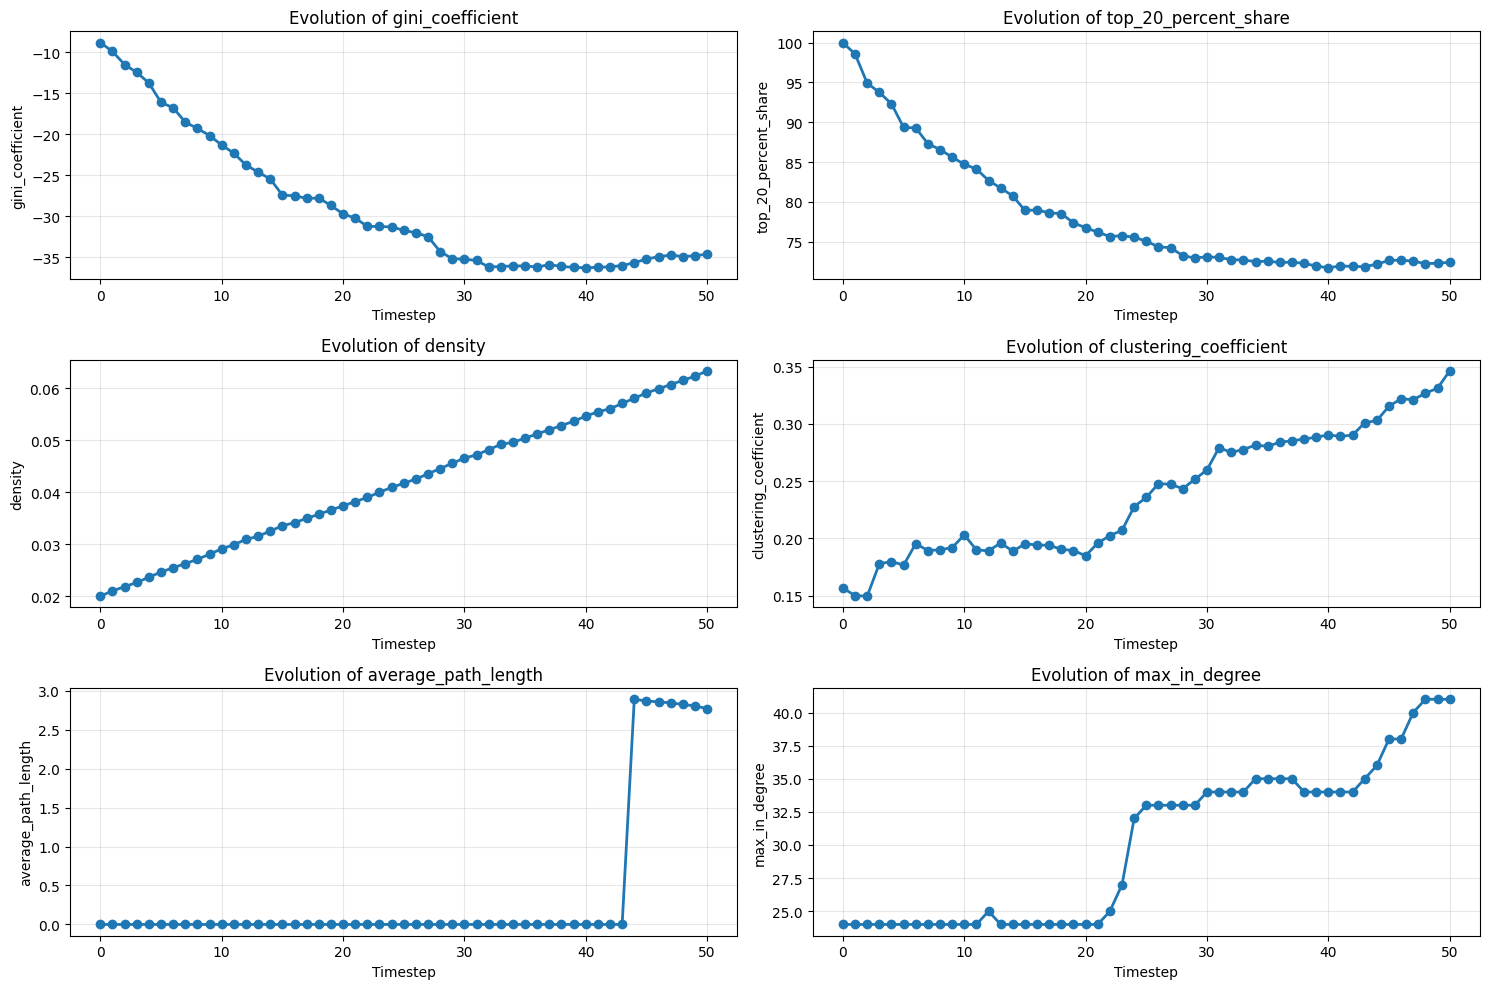

In [4]:
fig = plot_network_evolution(history_df)
plt.show()

### Law of the Few Analysis

We classify a network as following the Law of the Few when:
- The top 20% of nodes hold >= 80% of all incoming links.
- The Gini coefficient of in-degree is >= 0.6.

In [5]:
analysis = sim.analyze_law_of_few()
print("Law of the Few Analysis:")
for k, v in analysis.items():
    if k != 'top_nodes':
        print(f"  {k}: {v}")
print(f"\nTop 10 nodes by in-degree: {analysis['top_nodes']}")

Law of the Few Analysis:
  top_20_percent_share: 72.40829346092504
  gini_coefficient: -34.61881977671451
  avg_in_degree: 6.27
  max_in_degree: 41
  follows_law_of_few: False

Top 10 nodes by in-degree: [69, 86, 87, 17, 82, 14, 60, 28, 40, 91]


### Visualise the Final Network

Node colour reflects in-degree (darker = more incoming links). Node size also scales
with in-degree. Influencer nodes naturally attract more connections.

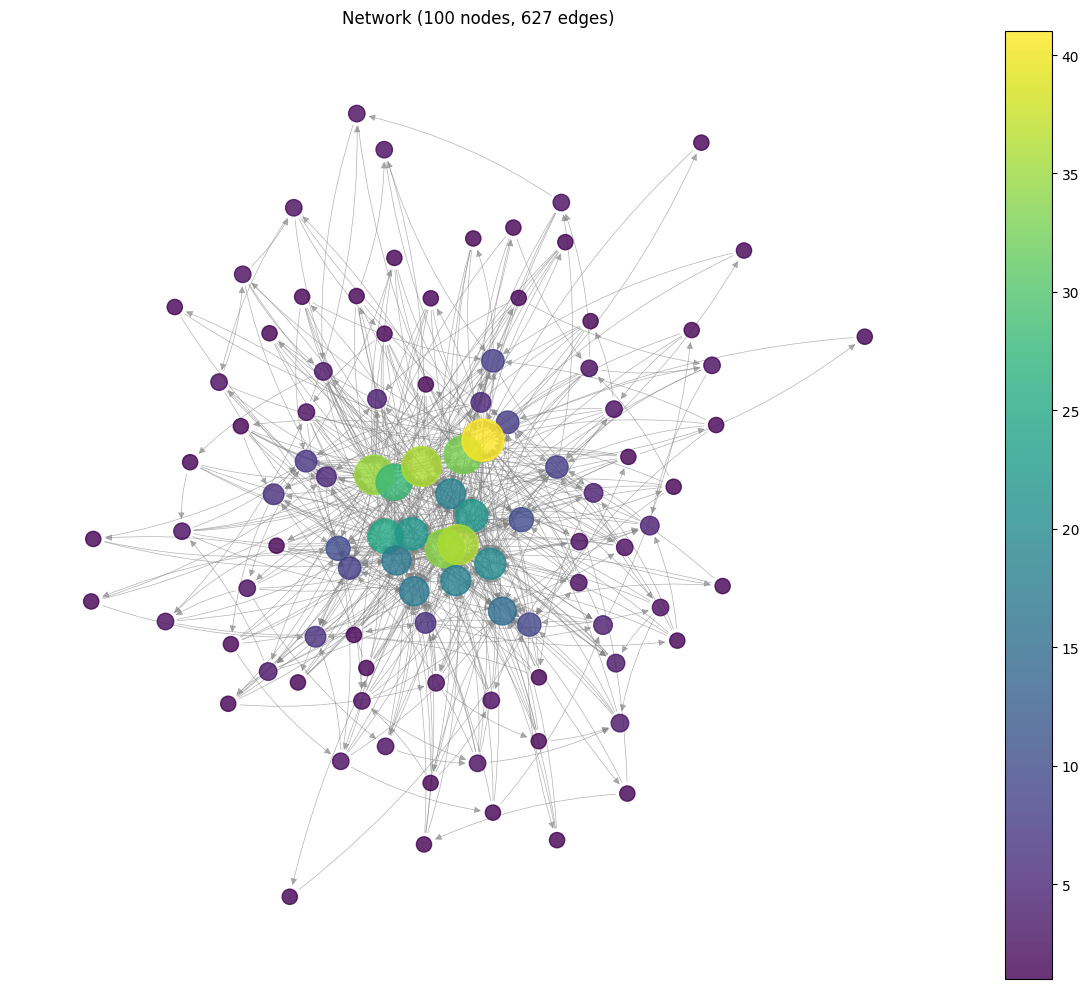

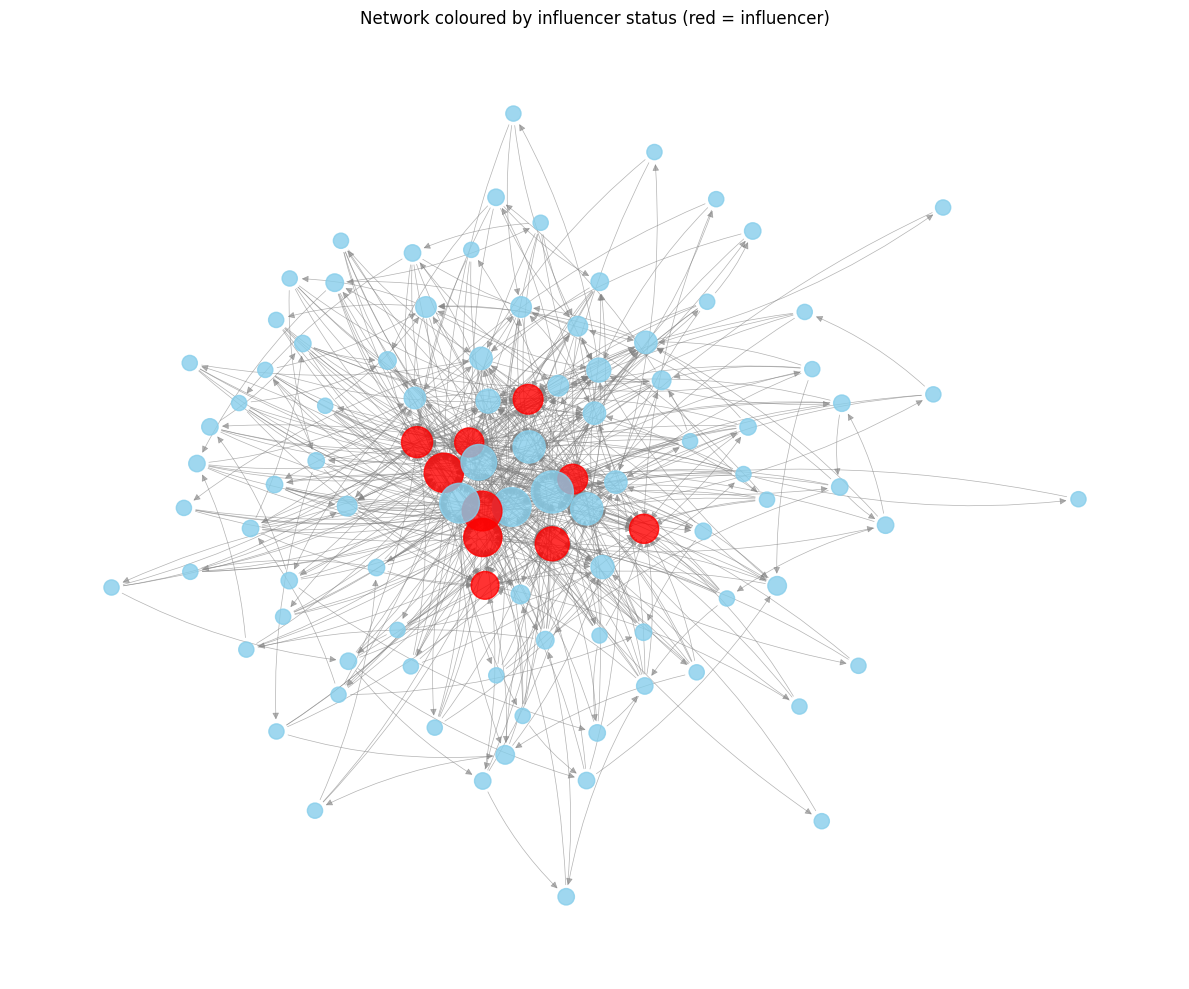

In [6]:
fig = sim.plot_network(color_by='in_degree', size_by='in_degree')
plt.show()

fig = sim.plot_network(color_by='influencer', size_by='in_degree')
plt.title('Network coloured by influencer status (red = influencer)')
plt.show()

## Part 2: Comparative Analysis

We sweep over `cost_parameter` and `heterogeneity_factor` to see how the network
structure responds. Higher costs should reduce link density, while higher heterogeneity
should strengthen the hub-spoke pattern.

In [7]:
parameter_variations = {
    'cost_parameter': [0.05, 0.1, 0.2, 0.3],
    'heterogeneity_factor': [1.0, 2.0, 3.0, 5.0],
}

results_df = sim.run_comparative_analysis(
    parameter_variations,
    n_steps=30,
    seeds=[42, 123, 456],
)

print(f"Comparative analysis: {len(results_df)} configurations tested.")
results_df.head(10)

Comparative analysis: 48 configurations tested.


,seed,cost_parameter,heterogeneity_factor,top_20_percent_share,gini_coefficient,avg_in_degree,max_in_degree,follows_law_of_few
0,42,0.05,1.0,72.234273,-36.524946,4.61,36,False
1,42,0.05,2.0,73.535792,-36.069414,4.61,27,False
2,42,0.05,3.0,73.101952,-35.236443,4.61,34,False
3,42,0.05,5.0,73.969631,-34.451193,4.61,31,False
4,42,0.10,1.0,72.234273,-36.524946,4.61,36,False
5,42,0.10,2.0,73.535792,-36.069414,4.61,27,False
6,42,0.10,3.0,73.101952,-35.236443,4.61,34,False
7,42,0.10,5.0,73.969631,-34.451193,4.61,31,False
8,42,0.20,1.0,72.234273,-36.524946,4.61,36,False
9,42,0.20,2.0,73.535792,-36.069414,4.61,27,False


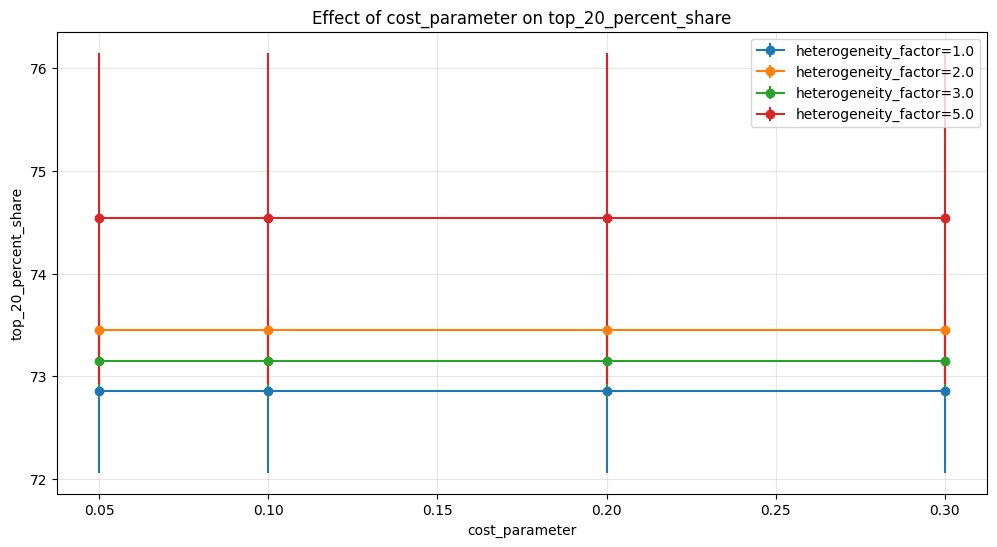

In [8]:
fig = plot_comparative_results(
    results_df,
    x_param='cost_parameter',
    target='top_20_percent_share',
    group_by='heterogeneity_factor',
)
plt.show()

## Part 3: Parameter Sensitivity Heatmap

A heatmap of the Gini coefficient indexed by cost and heterogeneity shows which
parameter regions produce the most unequal (hub-dominated) networks.

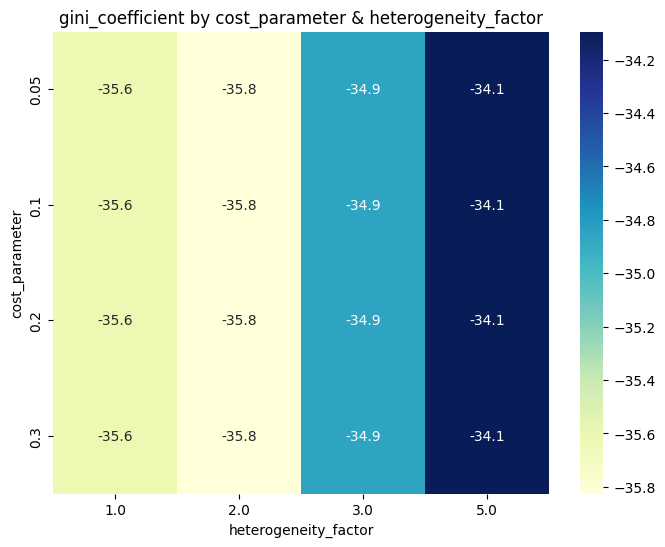

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_parameter_heatmap(
    results_df,
    row_param='cost_parameter',
    col_param='heterogeneity_factor',
    value='gini_coefficient',
    ax=ax,
)
plt.show()

## Convergence Check

We verify whether the baseline simulation has converged by checking the coefficient of
variation of key metrics over the last 10 time steps.

In [10]:
converged, details = sim.has_converged(window_size=10, threshold=0.02)
print(f"Converged: {converged}")
for k, v in details.items():
    print(f"  {k}: {v}")

Converged: False
  star_nodes_fraction_cv: 0.0
  star_nodes_fraction_converged: True
  clustering_coefficient_cv: 0.05585260479580646
  clustering_coefficient_converged: False
  average_path_length_cv: 0.6548433792624578
  average_path_length_converged: False
  network_density_cv: 0.042757811512212446
  network_density_converged: False
  gini_coefficient_cv: -0.016782922797802153
  gini_coefficient_converged: True
  top_20_percent_share_cv: 0.003995288133477674
  top_20_percent_share_converged: True
